In [1]:
import os
import requests
from dotenv import load_dotenv

load_dotenv()

api_token = os.getenv("ENTSOE_API_TOKEN")

if not api_token:
    raise ValueError("API token not found. Check your .env file.")

url = "https://web-api.tp.entsoe.eu/api"

params = {
    "securityToken": api_token,
    "documentType": "A44",
    "in_Domain": "10YNO-1--------2",
    "out_Domain": "10YNO-1--------2",
    "periodStart": "202610010000",
    "periodEnd": "202610020000"
}

response = requests.get(url, params=params, timeout=30)

print("Status code:", response.status_code)
print(response.text[:1000])

Status code: 200
<?xml version="1.0" encoding="utf-8"?>
  <Publication_MarketDocument xmlns="urn:iec62325.351:tc57wg16:451-3:publicationdocument:7:3">
    <mRID>34ead632f6e34c3fbe2d01eb6e26207c</mRID>
    <revisionNumber>1</revisionNumber>
    <type>A44</type>
    <sender_MarketParticipant.mRID codingScheme="A01">10X1001A1001A450</sender_MarketParticipant.mRID>
    <sender_MarketParticipant.marketRole.type>A32</sender_MarketParticipant.marketRole.type>
    <receiver_MarketParticipant.mRID codingScheme="A01">10X1001A1001A450</receiver_MarketParticipant.mRID>
    <receiver_MarketParticipant.marketRole.type>A33</receiver_MarketParticipant.marketRole.type>
    <createdDateTime>2026-10-20T11:44:21Z</createdDateTime>
    <period.timeInterval>
      <start>2026-09-30T22:00Z</start>
      <end>2026-10-02T22:00Z</end>
    </period.timeInterval>
      <TimeSeries>
        <mRID>1</mRID>
        <auction.type>A01</auction.type>
        <businessType>A62</businessType>
        <in_Domain.mRID codi

In [2]:
import pandas as pd
import xml.etree.ElementTree as ET

# Parse the XML response
root = ET.fromstring(response.content)

# XML namespace
ns = {"ns": root.tag.split("}")[0].strip("{")}

data = []

# Extract each time series
for series in root.findall("ns:TimeSeries", ns):
    for period in series.findall("ns:Period", ns):

        start = period.find("ns:timeInterval/ns:start", ns).text
        resolution = period.find("ns:resolution", ns).text

        for point in period.findall("ns:Point", ns):
            position = int(point.find("ns:position", ns).text)
            price = float(point.find("ns:price.amount", ns).text)

            data.append({
                "start": start,
                "resolution": resolution,
                "position": position,
                "price_EUR_MWh": price
            })

df = pd.DataFrame(data)

df.head()

,start,resolution,position,price_EUR_MWh
0,2026-09-30T22:00Z,PT15M,1,132.77
1,2026-09-30T22:00Z,PT15M,2,132.83
2,2026-09-30T22:00Z,PT15M,3,132.76
3,2026-09-30T22:00Z,PT15M,4,132.95
4,2026-09-30T22:00Z,PT15M,5,132.73


In [3]:
df["start"] = pd.to_datetime(df["start"], utc=True)

df["timestamp"] = df["start"] + (
    (df["position"] - 1) *
    df["resolution"].map({
        "PT15M": pd.Timedelta(minutes=15),
        "PT30M": pd.Timedelta(minutes=30),
        "PT60M": pd.Timedelta(hours=1)
    })
)

df["timestamp_norway"] = (
    df["timestamp"].dt.tz_convert("Europe/Oslo")
)

df = df.sort_values("timestamp").reset_index(drop=True)

df[["timestamp_norway", "price_EUR_MWh"]].head(10)

,timestamp_norway,price_EUR_MWh
0,2026-10-01 00:00:00+02:00,132.77
1,2026-10-01 00:00:00+02:00,132.77
2,2026-10-01 00:15:00+02:00,132.83
3,2026-10-01 00:15:00+02:00,132.83
4,2026-10-01 00:30:00+02:00,132.76
5,2026-10-01 00:30:00+02:00,132.76
6,2026-10-01 00:45:00+02:00,132.95
7,2026-10-01 00:45:00+02:00,132.95
8,2026-10-01 01:00:00+02:00,132.73
9,2026-10-01 01:00:00+02:00,132.73


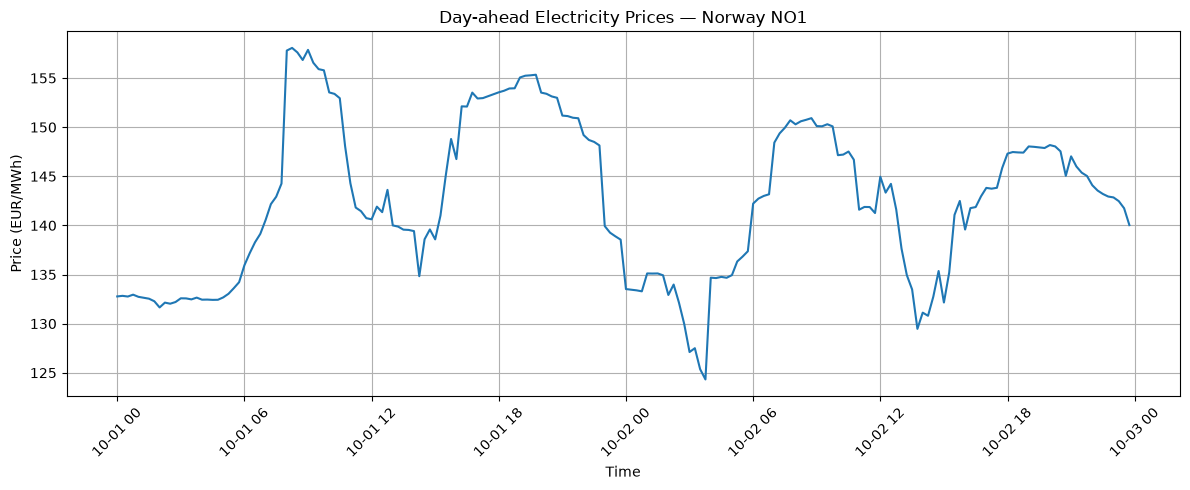

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    df["timestamp_norway"],
    df["price_EUR_MWh"]
)

plt.title("Day-ahead Electricity Prices — Norway NO1")
plt.xlabel("Time")
plt.ylabel("Price (EUR/MWh)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

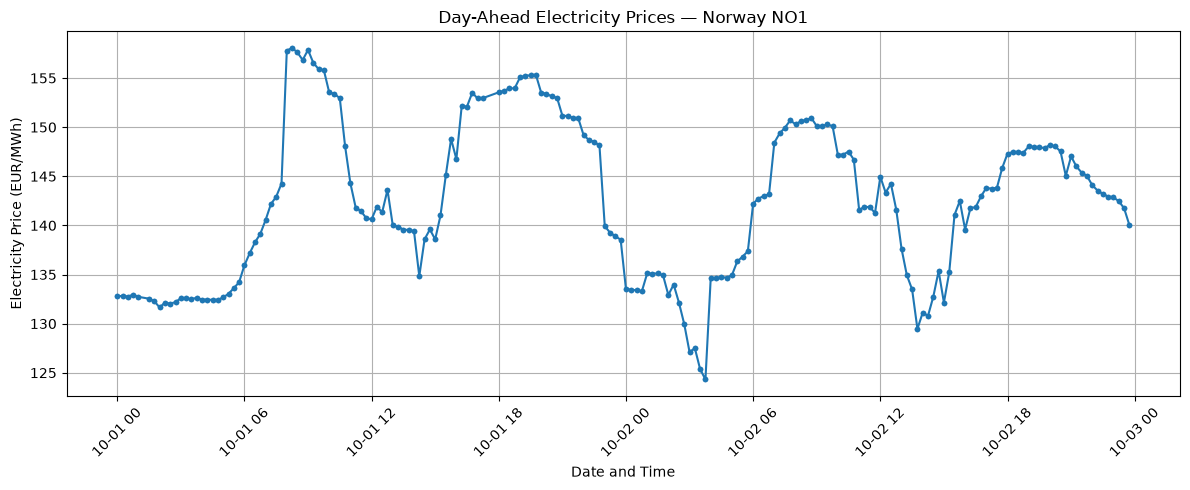

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    df["timestamp_norway"],
    df["price_EUR_MWh"],
    marker="o",
    markersize=3
)

plt.title("Day-Ahead Electricity Prices — Norway NO1")
plt.xlabel("Date and Time")
plt.ylabel("Electricity Price (EUR/MWh)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [6]:
from pathlib import Path

output_dir = Path("data")
output_dir.mkdir(exist_ok=True)

df.to_csv(output_dir / "entsoe_prices_NO1.csv", index=False)

print("Data saved successfully!")

Data saved successfully!


In [7]:
print("Number of observations:", len(df))
print("Columns:", df.columns.tolist())
print("Missing values:")
print(df.isnull().sum())

Number of observations: 378
Columns: ['start', 'resolution', 'position', 'price_EUR_MWh', 'timestamp', 'timestamp_norway']
Missing values:
start               0
resolution          0
position            0
price_EUR_MWh       0
timestamp           0
timestamp_norway    0
dtype: int64


In [8]:
print("First timestamp:", df["timestamp_norway"].min())
print("Last timestamp:", df["timestamp_norway"].max())

print("Unique timestamps:", df["timestamp"].nunique())
print("Duplicate timestamps:", df["timestamp"].duplicated().sum())

print("\nResolution counts:")
print(df["resolution"].value_counts())

First timestamp: 2026-10-01 00:00:00+02:00
Last timestamp: 2026-10-02 23:45:00+02:00
Unique timestamps: 189
Duplicate timestamps: 189

Resolution counts:
resolution
PT15M    378
Name: count, dtype: int64


In [9]:
# Show observations sharing the same timestamp
duplicates = df[
    df.duplicated(subset=["timestamp"], keep=False)
]

print(duplicates[
    ["timestamp_norway", "price_EUR_MWh"]
].head(12))

            timestamp_norway  price_EUR_MWh
0  2026-10-01 00:00:00+02:00         132.77
1  2026-10-01 00:00:00+02:00         132.77
2  2026-10-01 00:15:00+02:00         132.83
3  2026-10-01 00:15:00+02:00         132.83
4  2026-10-01 00:30:00+02:00         132.76
5  2026-10-01 00:30:00+02:00         132.76
6  2026-10-01 00:45:00+02:00         132.95
7  2026-10-01 00:45:00+02:00         132.95
8  2026-10-01 01:00:00+02:00         132.73
9  2026-10-01 01:00:00+02:00         132.73
10 2026-10-01 01:30:00+02:00         132.54
11 2026-10-01 01:30:00+02:00         132.54


In [10]:
price_check = df.groupby("timestamp")["price_EUR_MWh"].agg(
    ["count", "nunique", "min", "max"]
)

print(price_check.head(10))

print(
    "Timestamps with different prices:",
    (price_check["nunique"] > 1).sum()
)

                           count  nunique     min     max
timestamp                                                
2026-09-30 22:00:00+00:00      2        1  132.77  132.77
2026-09-30 22:15:00+00:00      2        1  132.83  132.83
2026-09-30 22:30:00+00:00      2        1  132.76  132.76
2026-09-30 22:45:00+00:00      2        1  132.95  132.95
2026-09-30 23:00:00+00:00      2        1  132.73  132.73
2026-09-30 23:30:00+00:00      2        1  132.54  132.54
2026-09-30 23:45:00+00:00      2        1  132.28  132.28
2026-10-01 00:00:00+00:00      2        1  131.65  131.65
2026-10-01 00:15:00+00:00      2        1  132.14  132.14
2026-10-01 00:30:00+00:00      2        1  132.03  132.03
Timestamps with different prices: 0


In [11]:
# Remove duplicate timestamps
df_clean = df.drop_duplicates(
    subset=["timestamp"],
    keep="first"
).copy()

# Sort chronologically
df_clean = df_clean.sort_values(
    "timestamp"
).reset_index(drop=True)

print("Original observations:", len(df))
print("Clean observations:", len(df_clean))
print("Remaining duplicates:",
      df_clean["timestamp"].duplicated().sum())

Original observations: 378
Clean observations: 189
Remaining duplicates: 0


In [12]:
# Generate expected 15-minute timestamps
expected = pd.date_range(
    start=df_clean["timestamp"].min(),
    end=df_clean["timestamp"].max(),
    freq="15min"
)

# Find missing timestamps
missing = expected.difference(
    pd.DatetimeIndex(df_clean["timestamp"])
)

print("Expected timestamps:", len(expected))
print("Actual timestamps:", len(df_clean))
print("Missing timestamps:", len(missing))

print("\nMissing intervals:")
print(missing.tz_convert("Europe/Oslo"))

Expected timestamps: 192
Actual timestamps: 189
Missing timestamps: 3

Missing intervals:
DatetimeIndex(['2026-10-01 01:15:00+02:00', '2026-10-01 17:30:00+02:00',
               '2026-10-01 17:45:00+02:00'],
              dtype='datetime64[us, Europe/Oslo]', freq=None)


In [13]:
from pathlib import Path

output_dir = Path("data")
output_dir.mkdir(exist_ok=True)

df_clean.to_csv(
    output_dir / "entsoe_prices_NO1_clean.csv",
    index=False
)

print("Cleaned dataset saved!")

Cleaned dataset saved!


In [4]:
import os
import sys
from pyspark.sql import SparkSession

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("IND320_Test")
    .getOrCreate()
)

print("Python:", sys.version)
print("Executable:", sys.executable)
print("Spark version:", spark.version)

Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
Executable: c:\Projects\IND320\.venv\Scripts\python.exe
Spark version: 3.5.1


In [5]:
test_df = spark.createDataFrame(
    [(1, "ENTSO-E"), (2, "Cassandra")],
    ["id", "source"]
)

test_df.show()

+---+---------+
| id|   source|
+---+---------+
|  1|  ENTSO-E|
|  2|Cassandra|
+---+---------+



In [6]:
import os
import sys
from pyspark.sql import SparkSession

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("IND320_Cassandra")
    .config(
        "spark.jars.packages",
        "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1"
    )
    .config(
        "spark.cassandra.connection.host",
        "127.0.0.1"
    )
    .config(
        "spark.cassandra.connection.port",
        "9042"
    )
    .getOrCreate()
)

print("Spark version:", spark.version)
print("Spark connected!")

Spark version: 3.5.1
Spark connected!


In [2]:
import os
import sys
from pyspark.sql import SparkSession

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("IND320_Cassandra")
    .config("spark.jars.ivy", "C:/Projects/ivy_cache")
    .config(
        "spark.jars.packages",
        "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1"
    )
    .config("spark.cassandra.connection.host", "127.0.0.1")
    .config("spark.cassandra.connection.port", "9042")
    .getOrCreate()
)

print("Spark version:", spark.version)
print("Loaded JARs:", spark.sparkContext._jsc.sc().listJars().toString())

Spark version: 3.5.1
Loaded JARs: Vector(spark://10.20.15.150:57998/jars/org.apache.cassandra_java-driver-core-shaded-4.18.1.jar, spark://10.20.15.150:57998/jars/org.apache.commons_commons-lang3-3.10.jar, spark://10.20.15.150:57998/jars/org.slf4j_slf4j-api-1.7.26.jar, spark://10.20.15.150:57998/jars/com.thoughtworks.paranamer_paranamer-2.8.jar, spark://10.20.15.150:57998/jars/org.hdrhistogram_HdrHistogram-2.1.12.jar, spark://10.20.15.150:57998/jars/org.apache.cassandra_java-driver-mapper-runtime-4.18.1.jar, spark://10.20.15.150:57998/jars/org.reactivestreams_reactive-streams-1.0.3.jar, spark://10.20.15.150:57998/jars/com.typesafe_config-1.4.1.jar, spark://10.20.15.150:57998/jars/org.scala-lang.modules_scala-collection-compat_2.12-2.11.0.jar, spark://10.20.15.150:57998/jars/com.datastax.oss_java-driver-shaded-guava-25.1-jre-graal-sub-1.jar, spark://10.20.15.150:57998/jars/com.datastax.spark_spark-cassandra-connector_2.12-3.5.1.jar, spark://10.20.15.150:57998/jars/org.scala-lang_scala-re

In [3]:
df_cassandra = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(
        keyspace="ind320",
        table="electricity_prices"
    )
    .load()
)

df_cassandra.printSchema()
df_cassandra.show(5)

root
 |-- timestamp_utc: timestamp (nullable = false)
 |-- price_eur_mwh: double (nullable = true)
 |-- timestamp_norway: string (nullable = true)

+-------------+-------------+----------------+
|timestamp_utc|price_eur_mwh|timestamp_norway|
+-------------+-------------+----------------+
+-------------+-------------+----------------+



In [4]:
import pandas as pd

df_prices = pd.read_csv("data/entsoe_prices_NO1_clean.csv")

print("Number of rows:", len(df_prices))
print("Columns:", df_prices.columns.tolist())

df_prices.head()

Number of rows: 189
Columns: ['start', 'resolution', 'position', 'price_EUR_MWh', 'timestamp', 'timestamp_norway']


,start,resolution,position,price_EUR_MWh,timestamp,timestamp_norway
0,2026-09-30 22:00:00+00:00,PT15M,1,132.77,2026-09-30 22:00:00+00:00,2026-10-01 00:00:00+02:00
1,2026-09-30 22:00:00+00:00,PT15M,2,132.83,2026-09-30 22:15:00+00:00,2026-10-01 00:15:00+02:00
2,2026-09-30 22:00:00+00:00,PT15M,3,132.76,2026-09-30 22:30:00+00:00,2026-10-01 00:30:00+02:00
3,2026-09-30 22:00:00+00:00,PT15M,4,132.95,2026-09-30 22:45:00+00:00,2026-10-01 00:45:00+02:00
4,2026-09-30 22:00:00+00:00,PT15M,5,132.73,2026-09-30 23:00:00+00:00,2026-10-01 01:00:00+02:00


In [5]:
df_prices["timestamp_utc"] = (
    pd.to_datetime(df_prices["timestamp"], utc=True)
    .dt.tz_localize(None)
)

df_prices["timestamp_norway"] = (
    pd.to_datetime(df_prices["timestamp"], utc=True)
    .dt.tz_convert("Europe/Oslo")
    .astype(str)
)

df_prices = df_prices.rename(
    columns={"price_EUR_MWh": "price_eur_mwh"}
)

df_ready = df_prices[
    ["timestamp_utc", "timestamp_norway", "price_eur_mwh"]
]

print(df_ready.head())
print("Rows:", len(df_ready))

        timestamp_utc           timestamp_norway  price_eur_mwh
0 2026-09-30 22:00:00  2026-10-01 00:00:00+02:00         132.77
1 2026-09-30 22:15:00  2026-10-01 00:15:00+02:00         132.83
2 2026-09-30 22:30:00  2026-10-01 00:30:00+02:00         132.76
3 2026-09-30 22:45:00  2026-10-01 00:45:00+02:00         132.95
4 2026-09-30 23:00:00  2026-10-01 01:00:00+02:00         132.73
Rows: 189


In [6]:
spark.conf.set("spark.sql.session.timeZone", "UTC")

spark_df = spark.createDataFrame(df_ready)

spark_df.printSchema()
spark_df.show(5, truncate=False)

root
 |-- timestamp_utc: timestamp (nullable = true)
 |-- timestamp_norway: string (nullable = true)
 |-- price_eur_mwh: double (nullable = true)

+-------------------+-------------------------+-------------+
|timestamp_utc      |timestamp_norway         |price_eur_mwh|
+-------------------+-------------------------+-------------+
|2026-09-30 20:00:00|2026-10-01 00:00:00+02:00|132.77       |
|2026-09-30 20:15:00|2026-10-01 00:15:00+02:00|132.83       |
|2026-09-30 20:30:00|2026-10-01 00:30:00+02:00|132.76       |
|2026-09-30 20:45:00|2026-10-01 00:45:00+02:00|132.95       |
|2026-09-30 21:00:00|2026-10-01 01:00:00+02:00|132.73       |
+-------------------+-------------------------+-------------+
only showing top 5 rows



In [7]:
import pandas as pd

# Set Spark's timezone to UTC
spark.conf.set("spark.sql.session.timeZone", "UTC")

# Read original timestamps as UTC
df_prices = pd.read_csv("data/entsoe_prices_NO1_clean.csv")

timestamps = pd.to_datetime(df_prices["timestamp"], utc=True)

df_ready = pd.DataFrame({
    "timestamp_utc": timestamps.dt.tz_localize(None),
    "timestamp_norway": timestamps.dt.tz_convert("Europe/Oslo").astype(str),
    "price_eur_mwh": df_prices["price_EUR_MWh"].astype(float)
})

# Convert to Spark, explicitly defining the schema
from pyspark.sql.types import (
    StructType, StructField, TimestampType,
    StringType, DoubleType
)

schema = StructType([
    StructField("timestamp_utc", TimestampType(), False),
    StructField("timestamp_norway", StringType(), True),
    StructField("price_eur_mwh", DoubleType(), True)
])

# Use timezone-aware UTC datetime objects
records = [
    (
        ts.to_pydatetime(),
        norway,
        float(price)
    )
    for ts, norway, price in zip(
        timestamps,
        df_ready["timestamp_norway"],
        df_ready["price_eur_mwh"]
    )
]

spark_df = spark.createDataFrame(records, schema=schema)

spark_df.show(5, truncate=False)

+-------------------+-------------------------+-------------+
|timestamp_utc      |timestamp_norway         |price_eur_mwh|
+-------------------+-------------------------+-------------+
|2026-09-30 22:00:00|2026-10-01 00:00:00+02:00|132.77       |
|2026-09-30 22:15:00|2026-10-01 00:15:00+02:00|132.83       |
|2026-09-30 22:30:00|2026-10-01 00:30:00+02:00|132.76       |
|2026-09-30 22:45:00|2026-10-01 00:45:00+02:00|132.95       |
|2026-09-30 23:00:00|2026-10-01 01:00:00+02:00|132.73       |
+-------------------+-------------------------+-------------+
only showing top 5 rows



In [8]:
(
    spark_df.write
    .format("org.apache.spark.sql.cassandra")
    .options(
        keyspace="ind320",
        table="electricity_prices"
    )
    .mode("append")
    .save()
)

print("Data written to Cassandra!")

Data written to Cassandra!


In [9]:
df_cassandra = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(
        keyspace="ind320",
        table="electricity_prices"
    )
    .load()
)

print("Rows in Cassandra:", df_cassandra.count())

df_cassandra.orderBy("timestamp_utc").show(5, truncate=False)

Rows in Cassandra: 189
+-------------------+-------------+-------------------------+
|timestamp_utc      |price_eur_mwh|timestamp_norway         |
+-------------------+-------------+-------------------------+
|2026-09-30 22:00:00|132.77       |2026-10-01 00:00:00+02:00|
|2026-09-30 22:15:00|132.83       |2026-10-01 00:15:00+02:00|
|2026-09-30 22:30:00|132.76       |2026-10-01 00:30:00+02:00|
|2026-09-30 22:45:00|132.95       |2026-10-01 00:45:00+02:00|
|2026-09-30 23:00:00|132.73       |2026-10-01 01:00:00+02:00|
+-------------------+-------------+-------------------------+
only showing top 5 rows



In [10]:
from pyspark.sql import functions as F

df_processed = (
    df_cassandra
    .withColumn(
        "date",
        F.to_date(
            F.to_timestamp(
                F.substring("timestamp_norway", 1, 19),
                "yyyy-MM-dd HH:mm:ss"
            )
        )
    )
    .groupBy("date")
    .agg(
        F.round(F.avg("price_eur_mwh"), 2).alias("avg_price"),
        F.round(F.min("price_eur_mwh"), 2).alias("min_price"),
        F.round(F.max("price_eur_mwh"), 2).alias("max_price"),
        F.count("*").alias("observations")
    )
    .orderBy("date")
)

df_processed.show()

+----------+---------+---------+---------+------------+
|      date|avg_price|min_price|max_price|observations|
+----------+---------+---------+---------+------------+
|2026-10-01|   143.77|   131.65|   158.07|          93|
|2026-10-02|   141.12|   124.32|   150.92|          96|
+----------+---------+---------+---------+------------+



### Step 8 — Store Processed Electricity Price Data in MongoDB Atlas

Convert the processed Spark DataFrame into Python dictionaries and prepare the daily electricity price statistics for storage in MongoDB Atlas.

In [11]:
# Convert Spark results to Pandas
df_mongo = df_processed.toPandas()

# Convert dates to strings for MongoDB
df_mongo["date"] = df_mongo["date"].astype(str)

# Convert to Python dictionaries
mongo_records = df_mongo.to_dict("records")

print(mongo_records)

[{'date': '2026-10-01', 'avg_price': 143.77, 'min_price': 131.65, 'max_price': 158.07, 'observations': 93}, {'date': '2026-10-02', 'avg_price': 141.12, 'min_price': 124.32, 'max_price': 150.92, 'observations': 96}]


### Step 9 — Connect to MongoDB Atlas and Store Processed Data

In [12]:
import os
from dotenv import load_dotenv
from pymongo import MongoClient

# Load credentials from .env
load_dotenv()

mongo_uri = os.getenv("MONGODB_URI")

if not mongo_uri:
    raise ValueError("MONGODB_URI not found in .env file")

# Connect to MongoDB Atlas
client = MongoClient(mongo_uri, serverSelectionTimeoutMS=10000)

# Verify connection
client.admin.command("ping")

print("Successfully connected to MongoDB Atlas!")

ServerSelectionTimeoutError: SSL handshake failed: ac-2g9tqol-shard-00-01.pkzkcqj.mongodb.net:27017: [SSL: TLSV1_ALERT_INTERNAL_ERROR] tlsv1 alert internal error (_ssl.c:1006) (configured timeouts: socketTimeoutMS: 20000.0ms, connectTimeoutMS: 20000.0ms),SSL handshake failed: ac-2g9tqol-shard-00-00.pkzkcqj.mongodb.net:27017: [SSL: TLSV1_ALERT_INTERNAL_ERROR] tlsv1 alert internal error (_ssl.c:1006) (configured timeouts: socketTimeoutMS: 20000.0ms, connectTimeoutMS: 20000.0ms),SSL handshake failed: ac-2g9tqol-shard-00-02.pkzkcqj.mongodb.net:27017: [SSL: TLSV1_ALERT_INTERNAL_ERROR] tlsv1 alert internal error (_ssl.c:1006) (configured timeouts: socketTimeoutMS: 20000.0ms, connectTimeoutMS: 20000.0ms), Timeout: 10.0s, Topology Description: <TopologyDescription id: 6ad77406363ed405582e8960, topology_type: ReplicaSetNoPrimary, servers: [<ServerDescription ('ac-2g9tqol-shard-00-00.pkzkcqj.mongodb.net', 27017) server_type: Unknown, rtt: None, error=AutoReconnect('SSL handshake failed: ac-2g9tq

In [13]:
import sys
import ssl
import pymongo
import certifi

print("Python:", sys.version)
print("OpenSSL:", ssl.OPENSSL_VERSION)
print("PyMongo:", pymongo.version)
print("Certificate bundle:", certifi.where())

Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
OpenSSL: OpenSSL 3.0.13 30 Jan 2024
PyMongo: 4.19.0
Certificate bundle: c:\Projects\IND320\.venv\Lib\site-packages\certifi\cacert.pem


In [15]:
from pymongo import MongoClient
from dotenv import load_dotenv
import os
import certifi

load_dotenv()

client = MongoClient(
    os.getenv("MONGODB_URI"),
    tls=True,
    tlsCAFile=certifi.where(),
    serverSelectionTimeoutMS=15000
)

client.admin.command("ping")

print("MongoDB connection successful!")

MongoDB connection successful!


### Step 10 — Insert Processed Electricity Price Data into MongoDB Atlas

In [16]:
# Select database and collection
db = client["ind320"]
collection = db["daily_electricity_prices"]

# Insert or update the processed records
for record in mongo_records:
    collection.update_one(
        {"date": record["date"]},
        {"$set": record},
        upsert=True
    )

print("Data successfully stored in MongoDB Atlas!")

# Verify the stored records
print("Number of documents:", collection.count_documents({}))

for document in collection.find({}, {"_id": 0}).sort("date", 1):
    print(document)

Data successfully stored in MongoDB Atlas!
Number of documents: 2
{'date': '2026-10-01', 'avg_price': 143.77, 'max_price': 158.07, 'min_price': 131.65, 'observations': 93}
{'date': '2026-10-02', 'avg_price': 141.12, 'max_price': 150.92, 'min_price': 124.32, 'observations': 96}
